<center><h1> IFT-6758 - Science des données  </h1></center>
<center><h2> Automne - 2022 </h2></center> 
<center><h3> Labo - 6</h3></center> 
<center><h3> </h3></center> 
<center><h3> scikit-learn: validation croisée, recherche d'hyperparamètres, pipelining et bootstrapping </h3></center> 



### Installation
Sur Google, colab `sklearn` est déjà installé

In [ ]:
!pip install sklearn

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/


### Importation

In [73]:
import sklearn

#Autres importations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

# [1] Validation croisée 

Scikit-learn possède une collection de classes qui peuvent être utilisées pour générer des listes d'indices de train/test pour les stratégies de validation croisée populaires.

Ils exposent une méthode de fractionnement (split/pli) qui accepte que l'ensemble de données d'entrée soit fractionné et donne les indices d'ensemble d'entraînement/test pour chaque itération de la stratégie de validation croisée choisie.

<a rel="K fold Cross Val">![](https://scikit-learn.org/stable/_images/grid_search_cross_validation.png)</a>

In [74]:
# Pour cet exercice, nous utilisons un petit jeu de données:
X = np.array(range(12))
y = np.array(["a", "a", "a", "a", "b", "b", "c", "c", "c", "c", "c", "c"])

###K-Fold (k-plis)

In [76]:
from sklearn.model_selection import KFold

k_fold = KFold(n_splits=2, shuffle=False)

for train_indices, test_indices in k_fold.split(X, y):
  print('train y: %s | test y: %s' % (y[train_indices], y[test_indices]))

train y: ['c' 'c' 'c' 'c' 'c' 'c'] | test y: ['a' 'a' 'a' 'a' 'b' 'b']
train y: ['a' 'a' 'a' 'a' 'b' 'b'] | test y: ['c' 'c' 'c' 'c' 'c' 'c']


###Repeated K-Fold

In [78]:
from sklearn.model_selection import RepeatedKFold

k_fold = RepeatedKFold(n_splits=3, n_repeats=10)

for train_indices, test_indices in k_fold.split(X, y):
  print('train y: %s | test y: %s' % (y[train_indices], y[test_indices]))

train y: ['a' 'a' 'a' 'b' 'c' 'c' 'c' 'c'] | test y: ['a' 'b' 'c' 'c']
train y: ['a' 'a' 'a' 'b' 'c' 'c' 'c' 'c'] | test y: ['a' 'b' 'c' 'c']
train y: ['a' 'a' 'b' 'b' 'c' 'c' 'c' 'c'] | test y: ['a' 'a' 'c' 'c']
train y: ['a' 'a' 'a' 'b' 'b' 'c' 'c' 'c'] | test y: ['a' 'c' 'c' 'c']
train y: ['a' 'a' 'b' 'b' 'c' 'c' 'c' 'c'] | test y: ['a' 'a' 'c' 'c']
train y: ['a' 'a' 'a' 'c' 'c' 'c' 'c' 'c'] | test y: ['a' 'b' 'b' 'c']
train y: ['a' 'a' 'b' 'b' 'c' 'c' 'c' 'c'] | test y: ['a' 'a' 'c' 'c']
train y: ['a' 'a' 'a' 'b' 'c' 'c' 'c' 'c'] | test y: ['a' 'b' 'c' 'c']
train y: ['a' 'a' 'a' 'b' 'c' 'c' 'c' 'c'] | test y: ['a' 'b' 'c' 'c']
train y: ['a' 'a' 'a' 'b' 'b' 'c' 'c' 'c'] | test y: ['a' 'c' 'c' 'c']
train y: ['a' 'a' 'a' 'b' 'c' 'c' 'c' 'c'] | test y: ['a' 'b' 'c' 'c']
train y: ['a' 'a' 'b' 'c' 'c' 'c' 'c' 'c'] | test y: ['a' 'a' 'b' 'c']
train y: ['a' 'a' 'a' 'b' 'c' 'c' 'c' 'c'] | test y: ['a' 'b' 'c' 'c']
train y: ['a' 'a' 'a' 'b' 'c' 'c' 'c' 'c'] | test y: ['a' 'b' 'c' 'c']
train 

### Stratified K-Fold

![](https://miro.medium.com/max/562/0*QKJTHrcriSx2ZNYr.png)



In [79]:
from sklearn.model_selection import StratifiedKFold

stratified_k_fold = StratifiedKFold(n_splits=2, shuffle=True)

for train_indices, test_indices in stratified_k_fold.split(X, y):
  print('train y: %s | test y: %s' % (y[train_indices], y[test_indices]))

train y: ['a' 'a' 'b' 'c' 'c' 'c'] | test y: ['a' 'a' 'b' 'c' 'c' 'c']
train y: ['a' 'a' 'b' 'c' 'c' 'c'] | test y: ['a' 'a' 'b' 'c' 'c' 'c']



Lisez à propos de ces autres façons de diviser votre ensemble de données et pensez aux cas où vous les utiliseriez.
Essayez de les utiliser sur l'ensemble de données de jouets ci-dessus.

*   [PredefinedSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.PredefinedSplit.html)
*   [LeaveOneGroupOut](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.LeaveOneGroupOut.html)
*   [GroupShuffleSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html)


##`cross_val_score()`

Il s'agit d'une fonction couramment utilisée pour évaluer directement les scores de validation croisée en transmettant votre modèle (estimateur), les données et les fractionnements de validation croisée.

Documentation: [cross_val_score](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)

Applying chosen CV scheme on a dataset using `cross_val_score` 

In [82]:
from scipy.stats import sem
from numpy import mean
from numpy import std
from sklearn.datasets import make_classification
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
  
# Créer un jeu de données
X, y = make_classification(n_samples=1000, n_features=20, random_state=42)

# Évaluer un modèle avec un nombre donné de divisions

# Créer le séparateur à l'aide de la validation croisée choisie
cv = KFold(n_splits=10, shuffle=True, random_state=1)
# Créer un modèle
model = LogisticRegression()
# Évaluer le modèle
scores = cross_val_score(model, X, y, scoring='accuracy', cv=cv, n_jobs=-1)

print('Précisions des plis individuels: ', scores)

print('Précision: moyenne={:0.4f}, erreur={:0.4f}'.format(mean(scores), sem(scores)))


Précisions des plis individuels:  [0.93 0.85 0.85 0.9  0.85 0.92 0.89 0.86 0.84 0.82]
Précision: moyenne=0.8710, erreur=0.0116


Applying CV for different values of $k$

Quand k= 2 précision: moyenne=0.8640, erreur=0.0000
Quand k= 3 précision: moyenne=0.8640, erreur=0.0113
Quand k= 4 précision: moyenne=0.8680, erreur=0.0078
Quand k= 5 précision: moyenne=0.8680, erreur=0.0101
Quand k= 6 précision: moyenne=0.8639, erreur=0.0128
Quand k= 7 précision: moyenne=0.8690, erreur=0.0074
Quand k= 8 précision: moyenne=0.8660, erreur=0.0077
Quand k= 9 précision: moyenne=0.8670, erreur=0.0092
Quand k=10 précision: moyenne=0.8710, erreur=0.0116
Quand k=11 précision: moyenne=0.8680, erreur=0.0091
Quand k=12 précision: moyenne=0.8680, erreur=0.0103
Quand k=13 précision: moyenne=0.8690, erreur=0.0085
Quand k=14 précision: moyenne=0.8669, erreur=0.0087
Quand k=15 précision: moyenne=0.8699, erreur=0.0108
Quand k=16 précision: moyenne=0.8690, erreur=0.0083
Quand k=17 précision: moyenne=0.8709, erreur=0.0096
Quand k=18 précision: moyenne=0.8660, erreur=0.0104
Quand k=19 précision: moyenne=0.8689, erreur=0.0094


/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:36: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.


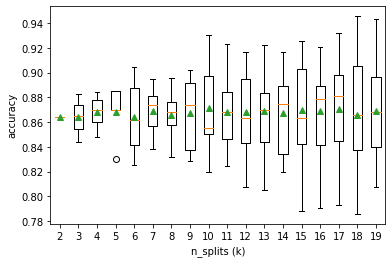

In [84]:
from scipy.stats import sem
from numpy import mean
from numpy import std
from sklearn.datasets import make_classification
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
 
# Évaluer un modèle avec un nombre donné de divisions

def evaluate_model(X, y, n_splits):
	# Create the splitter using the chosen cross-validation
	cv = KFold(n_splits=n_splits, shuffle=True, random_state=1)
	# Create model
	model = LogisticRegression()
	# Evaluate model
	scores = cross_val_score(model, X, y, scoring='accuracy', cv=cv, n_jobs=-1)
	return scores
 
# Créer un jeu de données
X, y = make_classification(n_samples=1000, n_features=20, random_state=42)

# Créer des valeurs possibles pour n_splits (k)
n_splits = range(2,20)
results = list()

for k in n_splits:
	# Évaluer en utilisant un nombre donné de plis
	scores = evaluate_model(X, y, k)
	# Résumer
	print('Quand k={:2d} précision: moyenne={:0.4f}, erreur={:0.4f}'.format(k, mean(scores), sem(scores)))
	# Stockez 
	results.append(scores)

# Tracez les résultats
plt.boxplot(np.array(results), labels=[str(k) for k in n_splits], showmeans=True)
plt.xlabel('n_splits (k)')
plt.ylabel('accuracy')
plt.show()


* Selon vous, quelle est la bonne valeur de $k$ pour le CV $k$-plis ?
* Essayez de modifier le schéma de CV et observez le changement dans les scores, le cas échéant.
* Lisez la documentation sur [cross_val_predict](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_predict.html) et comprenez la différence par rapport à `cross_val_score`.


##`cross_validate()`

Il s'agit d'une fonction permettant d'évaluer les scores de validation croisée de manière plus complète et avec plus de contrôle. Une autre façon d'utiliser le CV.

Documentation: [cross_val_score](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html)

In [87]:
from scipy.stats import sem
from numpy import mean
from numpy import std
from sklearn.datasets import make_classification
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_validate
from sklearn.linear_model import LogisticRegression
  
# Créer un jeu de données
X, y = make_classification(n_samples=1000, n_features=20, random_state=42)

# Évaluer un modèle avec un nombre donné de divisions

# Créer un modèle
model = LogisticRegression()

# Évaluer le modèle
cv_results = cross_validate(model, X, y, cv=10)

# Imprimer les champs du dictionnaire de résultats
print('Champs de résultat: ', cv_results.keys())

print('Précisions des plis individuels :', cv_results['test_score'])

scores = cv_results['test_score']

print('Précision: moyenne={:0.4f}, erreur={:0.4f}'.format(mean(scores), sem(scores)))


Champs de résultat:  dict_keys(['fit_time', 'score_time', 'test_score'])
Précisions des plis individuels : [0.88 0.91 0.92 0.89 0.89 0.85 0.8  0.85 0.85 0.85]
Précision: moyenne=0.8690, erreur=0.0113


Utiliser d'autres scores avec `cross_validate`

In [90]:
from sklearn import datasets
from sklearn import linear_model
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer

from sklearn.metrics import confusion_matrix
from sklearn.svm import LinearSVC

diabetes = datasets.load_diabetes()
X = diabetes.data[:150]
y = diabetes.target[:150]

model = linear_model.LinearRegression()

cv_scores = cross_validate(model, X, y, cv=3,
                        scoring=('r2', 'neg_mean_squared_error'),
                        return_train_score=True)

print('Train -MSE scores: ', cv_scores['train_neg_mean_squared_error'])
print('Test  -MSE scores: ',cv_scores['test_neg_mean_squared_error'])

print('Train R2 scores  : ',cv_scores['train_r2'])
print('Test  R2 scores  : ',cv_scores['test_r2'])

Train -MSE scores:  [-2784.602992   -2426.18087377 -2451.14250948]
Test  -MSE scores:  [-2727.7130097  -3481.76305373 -3524.64743077]
Train R2 scores  :  [0.515968   0.60652691 0.48251957]
Test  R2 scores  :  [0.49843203 0.1037956  0.44394338]


{'fit_time': array([0.00133491, 0.00123835, 0.00099373]),
 'score_time': array([0.01146793, 0.00093126, 0.0080812 ]),
 'test_r2': array([0.49843203, 0.1037956 , 0.44394338]),
 'train_r2': array([0.515968  , 0.60652691, 0.48251957]),
 'test_neg_mean_squared_error': array([-2727.7130097 , -3481.76305373, -3524.64743077]),
 'train_neg_mean_squared_error': array([-2784.602992  , -2426.18087377, -2451.14250948])}

# [2] Recherche d'hyperparamètres


Il existe d'autres classes qui ont un CV intégré qui peut être utilisé pour la recherche d'hyperparamètres.

### (a) Grid Search

scikit-learn fournit un objet qui, compte tenu des données, calcule le score lors de l'ajustement d'un estimateur sur une grille de paramètres et choisit les paramètres pour maximiser le score de validation croisée. Cet objet prend un estimateur lors de la construction et expose une API d'estimateur :

In [91]:
from sklearn import datasets

# Chargement du jeu de données Digits
digits = datasets.load_digits()

# Pour appliquer un classifieur sur ces données, il faut aplatir l'image, pour
# transformer les données dans une matrice (échantillons, caractéristiques) :
n_samples = len(digits.images)
X = digits.images.reshape((n_samples, -1))
y = digits.target

X[9] = 


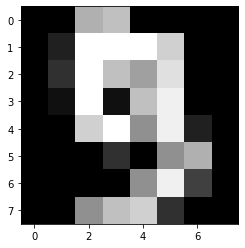

y = [0 1 2 3 4 5 6 7 8 9 0 1 2 3 4 5 6 7 8 9]


In [92]:
# Qu'est-ce que le jeu de données 'digits' ?
from matplotlib import pyplot as plt
idx = 9
print(f'X[{idx}] = ')
plt.imshow(digits.images[idx], cmap='gray')
plt.show()
print(f'y = {y[:20]}')

In [94]:
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report
from sklearn.svm import SVC

# Diviser le jeu de données en deux parties égales
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.5, random_state=0)

# Définir les paramètres par validation croisée
tuned_parameters = [
  {'kernel': ['rbf'],
  'gamma': [1e-3, 1e-4],
  'C': [1, 10, 100, 1000]},
  
  {'kernel': ['linear'],
   'C': [1, 10, 100, 1000]},
]

metric = 'f1_macro'

cv_strategy = StratifiedKFold(n_splits=10, shuffle=True)

grid_search = GridSearchCV(
    SVC(), tuned_parameters, scoring=metric, cv=cv_strategy
)
grid_search.fit(X_train, y_train);
print('Finished!')

Finished!


In [96]:
print("Meilleur jeu de paramètres trouvé sur le jeu de développement: ")
print()
print(grid_search.best_params_)
print(grid_search.best_score_)

Meilleur jeu de paramètres trouvé sur le jeu de développement: 

{'C': 10, 'gamma': 0.001, 'kernel': 'rbf'}
0.985129467382799


In [99]:
print("Grille des scores sur l'ensemble de development:")
print()
means = grid_search.cv_results_['mean_test_score']
stds = grid_search.cv_results_['std_test_score']
for mean, std, params in zip(means, stds, grid_search.cv_results_['params']):
    print("%0.3f (+/-%0.03f) for %r"
          % (mean, std * 2, params))

Grille des scores sur l'ensemble de development:

0.983 (+/-0.023) for {'C': 1, 'gamma': 0.001, 'kernel': 'rbf'}
0.958 (+/-0.035) for {'C': 1, 'gamma': 0.0001, 'kernel': 'rbf'}
0.985 (+/-0.014) for {'C': 10, 'gamma': 0.001, 'kernel': 'rbf'}
0.984 (+/-0.018) for {'C': 10, 'gamma': 0.0001, 'kernel': 'rbf'}
0.985 (+/-0.014) for {'C': 100, 'gamma': 0.001, 'kernel': 'rbf'}
0.985 (+/-0.015) for {'C': 100, 'gamma': 0.0001, 'kernel': 'rbf'}
0.985 (+/-0.014) for {'C': 1000, 'gamma': 0.001, 'kernel': 'rbf'}
0.985 (+/-0.015) for {'C': 1000, 'gamma': 0.0001, 'kernel': 'rbf'}
0.976 (+/-0.023) for {'C': 1, 'kernel': 'linear'}
0.976 (+/-0.023) for {'C': 10, 'kernel': 'linear'}
0.976 (+/-0.023) for {'C': 100, 'kernel': 'linear'}
0.976 (+/-0.023) for {'C': 1000, 'kernel': 'linear'}


In [101]:
print("Rapport de classification détaillé :")
print()
print("Le modèle est entraîné sur l'ensemble de développement complet.")
print("Les scores sont évalulés sur l'ensemble de l'évaluation complète.")
print()
y_true, y_pred = y_test, grid_search.predict(X_test)
print(classification_report(y_true, y_pred))
print()

Rapport de classification détaillé :

Le modèle est entraîné sur l'ensemble de développement complet.
Les scores sont évalulés sur l'ensemble de l'évaluation complète.

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        89
           1       0.97      1.00      0.98        90
           2       0.99      0.98      0.98        92
           3       1.00      0.99      0.99        93
           4       1.00      1.00      1.00        76
           5       0.99      0.98      0.99       108
           6       0.99      1.00      0.99        89
           7       0.99      1.00      0.99        78
           8       1.00      0.98      0.99        92
           9       0.99      0.99      0.99        92

    accuracy                           0.99       899
   macro avg       0.99      0.99      0.99       899
weighted avg       0.99      0.99      0.99       899




### (b) Random Search

Peut-on faire mieux avec une recherche aléatoire?

In [106]:
from sklearn.model_selection import RandomizedSearchCV

# Quelle est la taille de cet espace de paramètres ?
tuned_parameters = [
  {'kernel': ['rbf'],
  'gamma': np.logspace(-3, -4, num=50),
  'C': np.logspace(0, 3, num=50)},
  
  {'kernel': ['linear'],
   'C': np.logspace(0, 3, num=50)},
]

grid_search = RandomizedSearchCV(
    SVC(), tuned_parameters, n_iter=16, scoring=metric, cv=cv_strategy, 
)
grid_search.fit(X_train, y_train);
print('Finished!')

Finished!


In [107]:
print("Meilleur ensemble de paramètres trouvé sur l'ensemble de développement:")
print()
print(grid_search.best_params_)
print(grid_search.best_score_)

Meilleur ensemble de paramètres trouvé sur l'ensemble de développement:

{'kernel': 'rbf', 'gamma': 0.0002442053094548652, 'C': 16.768329368110084}
0.9897116496484177


In [108]:
print("Rapport de classification détaillé :")
print()
print("Le modèle est entraîné sur l'ensemble de développement complet.")
print("Les scores sont évalulés sur l'ensemble de l'évaluation complète.")
print()
y_true, y_pred = y_test, grid_search.predict(X_test)
print(classification_report(y_true, y_pred))
print()

Rapport de classification détaillé :

Le modèle est entraîné sur l'ensemble de développement complet.
Les scores sont évalulés sur l'ensemble de l'évaluation complète.

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        89
           1       0.96      1.00      0.98        90
           2       0.99      0.99      0.99        92
           3       0.99      0.99      0.99        93
           4       1.00      1.00      1.00        76
           5       0.96      0.98      0.97       108
           6       0.99      0.99      0.99        89
           7       0.99      1.00      0.99        78
           8       1.00      0.93      0.97        92
           9       0.99      0.98      0.98        92

    accuracy                           0.99       899
   macro avg       0.99      0.99      0.99       899
weighted avg       0.99      0.99      0.99       899




# [3] Pipelining

Pipeline peut être utilisé pour enchaîner plusieurs estimateurs en un seul.

Ceci est utile car il y a souvent une séquence fixe d'étapes dans le traitement des données, par exemple la sélection des caractéristiques, la normalisation et la classification. Pipeline a plusieurs objectifs ici:

* *Commodité et encapsulation* - besoin d'appeler fit et de prédire une fois sur vos données

* *Sélection conjointe des paramètres* - peut effectuer une recherche de grille sur les paramètres de tous les estimateurs à la fois.

* *Sécurité* - Évitez les fuites de statistiques de vos données de test dans le modèle formé lors de la validation croisée


## (a) `Pipeline` class

In [110]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn import datasets

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.pipeline import Pipeline

from sklearn.model_selection import GridSearchCV

from sklearn.metrics import accuracy_score


# Define a pipeline with StandardScaler
# and classifier regularization.

sclr = StandardScaler()

# set the tolerance to a large value to make the example faster
logistic = LogisticRegression(max_iter=10000, tol=0.1)

pipe = Pipeline(steps=[
  ('scaler', sclr),
  ('logistic', logistic)
])

X, y = datasets.load_digits(return_X_y=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.5, random_state=0)

# Parameters of pipelines can be set using ‘__’ separated parameter names:

# Note: C is a hyperparameter, i.e the inverse of regularization strength
# Ref: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
param_grid = {
    'logistic__C': np.logspace(-4, 4, 4),
    'scaler__with_std': [False, True],
    'scaler__with_mean': [False, True]
}

search = GridSearchCV(pipe, param_grid, n_jobs=-1)
search.fit(X_train, y_train);

In [111]:
print("Best parameter (CV score=%0.3f):" % search.best_score_)
print(search.best_params_)

Best parameter (CV score=0.967):
{'logistic__C': 0.046415888336127774, 'scaler__with_mean': True, 'scaler__with_std': False}


In [112]:
# Predict the labels of test set using the trained "pipeline"
y_predicted = search.predict(X_test)
y_predicted

array([2, 8, 2, 6, 6, 7, 1, 9, 8, 5, 2, 8, 6, 6, 6, 6, 1, 0, 5, 8, 8, 7,
       8, 4, 7, 5, 4, 9, 2, 9, 4, 7, 6, 8, 9, 4, 3, 1, 0, 1, 8, 6, 7, 7,
       1, 0, 7, 6, 2, 1, 9, 6, 7, 9, 0, 0, 5, 1, 6, 3, 0, 2, 3, 4, 1, 9,
       2, 6, 9, 1, 8, 3, 5, 1, 2, 8, 2, 2, 9, 7, 2, 3, 6, 0, 5, 3, 7, 5,
       1, 2, 9, 9, 3, 1, 4, 7, 4, 8, 5, 8, 5, 5, 2, 5, 9, 0, 7, 1, 4, 7,
       3, 4, 8, 9, 7, 9, 8, 2, 1, 5, 2, 5, 5, 4, 1, 7, 0, 6, 1, 5, 5, 9,
       9, 5, 9, 9, 5, 7, 5, 6, 2, 8, 6, 9, 6, 1, 5, 1, 5, 9, 9, 1, 5, 3,
       6, 1, 8, 9, 8, 7, 6, 7, 6, 5, 6, 0, 8, 8, 9, 8, 6, 1, 0, 4, 1, 6,
       3, 9, 6, 7, 4, 9, 6, 3, 0, 3, 3, 3, 0, 7, 7, 5, 7, 8, 0, 7, 8, 9,
       6, 4, 5, 0, 1, 4, 6, 4, 3, 3, 0, 9, 5, 3, 2, 1, 4, 2, 1, 6, 8, 9,
       2, 4, 9, 3, 7, 6, 2, 3, 3, 1, 6, 9, 3, 6, 3, 2, 2, 0, 7, 6, 1, 1,
       9, 7, 2, 7, 8, 5, 5, 7, 5, 2, 3, 7, 2, 7, 5, 5, 7, 0, 9, 1, 6, 5,
       9, 7, 4, 3, 8, 0, 3, 6, 4, 6, 3, 2, 6, 8, 8, 8, 4, 6, 7, 5, 2, 4,
       5, 3, 2, 4, 6, 9, 4, 5, 4, 3, 4, 6, 2, 9, 0,

In [113]:
# Accuracy score (between 0 and 1) of the predictions compared to actual labels
accuracy_score(y_test, y_predicted)

0.9588431590656284

##(b) `make_pipeline()`

Une version compacte et plus simple pour implémenter un pipeline.

In [116]:
from sklearn.pipeline import make_pipeline

from sklearn.metrics import accuracy_score

# Make pipeline by stacking 
model_pipeline = make_pipeline(StandardScaler(), LogisticRegression())   #OneHotEncoder(), LabelEncoder(), etc can as well be used when needed

# Fit data in pipeline
model_pipeline.fit(X_train, y_train)

# Predict on test set
y_predicted = model_pipeline.predict(X_test)

# Score your predictions to see how well your model perforomed
print(accuracy_score(y_test, y_predicted))

# Alternative score as a percentage
#print(accuracy_score(y_test, y_predicted) * 100)

0.96440489432703


In [115]:
make_pipeline(StandardScaler(), LogisticRegression()) 

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression())])

`make_pipeline` ne permet pas de nommer les estimateurs

#[4] Inférence Statistique : Bootstrapping et Intervalles de Confiance (IC)

##(a) IC de précision d'un classificateur simple

*Resampling* rééchantillonne les points dans l'ensemble de données donné, avec remplacements selon le principe du bootstrap.

In [117]:
from sklearn.utils import resample
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

In [118]:
data = pd.read_csv('https://raw.githubusercontent.com/Jhelum-Ch/DataScience_IFT6758/gh-pages/media/diabetes.csv', header=None)
values = data.values

In [119]:
values.shape

(768, 9)

In [ ]:
values[0] # 8 features ---> 1 output label (0/1)

array([  6.   , 148.   ,  72.   ,  35.   ,   0.   ,  33.6  ,   0.627,
        50.   ,   1.   ])

Fonction Sklearn utilisée dans le bootstrap :`resample()` [See documentation](https://scikit-learn.org/stable/modules/generated/sklearn.utils.resample.html)

In [120]:
# Bootstrap configuration
num_iterations = 1000
num_samples = int(len(data)/ 2)    # Pick a training set with size of 50% of the dataset

In [122]:
# Run the bootstrap

scores = []

for i in range(num_iterations):
  
  # Prepare train and test sets
  train = resample(values, n_samples=num_samples)
  test = pd.concat([data,pd.DataFrame(train)]).drop_duplicates(keep=False).values            #Consider all the samples other than those in the train set as test set
 
	# Fit model
  model = DecisionTreeClassifier()
  model.fit(train[:,:-1], train[:,-1])
	
  # Evaluate model
  predictions = model.predict(test[:,:-1])
  score = accuracy_score(test[:,-1], predictions)

  scores.append(score)

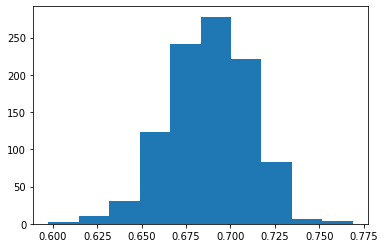

In [123]:
# plot scores
plt.hist(scores);

In [125]:
# Confidence interval

confidence_percentage = 95

# p-values
p = (100-confidence_percentage)/2 

# Quartiles
lower = max(0.0, np.percentile(scores, p))
upper = min(1.0, np.percentile(scores, 100 - p))

print('Classifier Accuracy : ({:d}%) confidence interval = [{:.1f}%,{:.1f}%]'.format(int(confidence_percentage), lower*100, upper*100))

Classifier Accuracy : (95%) confidence interval = [64.2%,73.0%]


Une confiance de 95% nous aide à choisir un intervalle dans lequel nous sommes sûrs à 95% de nos valeurs correctes ou `true`.

Visualisation de l'intervalle sur les résultats du bootstrap



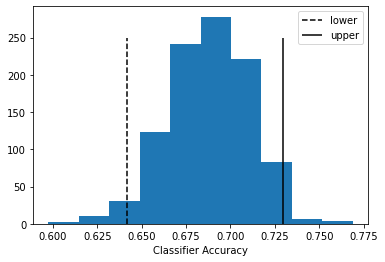

In [126]:
plt.vlines(lower,0,250, linestyles='--', label='lower')
plt.vlines(upper,0,250, label='upper')
plt.xlabel('Classifier Accuracy')
plt.legend(loc='best')
plt.hist(scores);

##(b) Visualisation de l'IC d'une régression linéaire

In [127]:
from sklearn.linear_model import LinearRegression
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [128]:
num_iterations = 1000

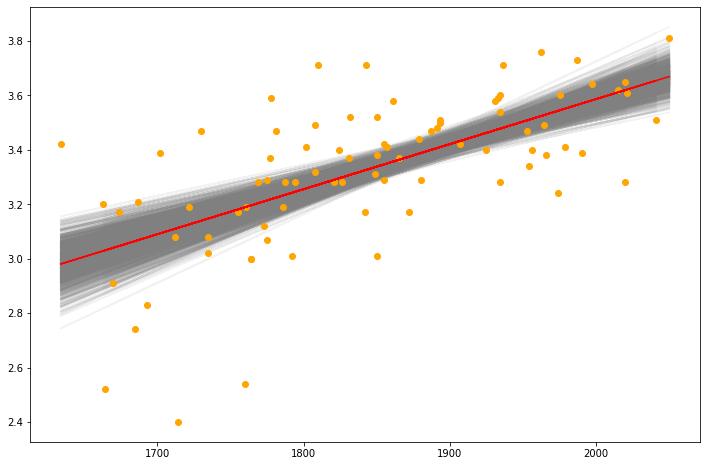

In [129]:

# Load data into dataframe
sat_gpa = pd.read_csv('https://raw.githubusercontent.com/Jhelum-Ch/DataScience_IFT6758/gh-pages/media/sat-gpa.csv')
X,y = sat_gpa.SAT.values, sat_gpa.GPA.values 

# Reshape X to prepare it for regression
X = X.reshape(-1,1)

plt.figure(figsize=(12,8))


# Bootstrapping loop
for i in range(0, num_iterations):
 
    sampled_index = np.random.choice(range(0, len(y)), len(y))

    X_samples = X[sampled_index]
    y_samples = y[sampled_index]    

    lr = LinearRegression()
    lr.fit(X_samples, y_samples)
    plt.plot(X, lr.predict(X), color='grey', alpha=0.1, zorder=1)

# Plot the data points
plt.scatter(X,y, marker='o', color='orange', zorder=4)

# Fit Regression model for the entre data
lr = LinearRegression()
lr.fit(X, y)
plt.plot(X, lr.predict(X), color='red', zorder=5);

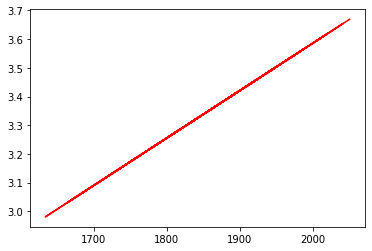

In [130]:
lr = LinearRegression()
lr.fit(X, y)
plt.plot(X, lr.predict(X), color='red', zorder=2);

La pente de la fonction d'hypothèse de régression linéaire est désignée par le **coefficient de régression linéaire**(coef), et le terme constant de la fonction d'hypothèse de régression linéaire est appelé **intersection de régression** (intercept).

In [131]:
lr.coef_

array([0.00165569])

In [132]:
lr.intercept_

0.2750402996602799

Observez l'étendue de la pente de la ligne de régression dans le tracé tel que défini par les lignes de régression bootstrap.

Si vous aimez explorer plus quantitativement :

In [ ]:
from scipy.stats import linregress

X,y = sat_gpa.SAT.values, sat_gpa.GPA.values 
slope, intercept, r, p, stderr = linregress(X.squeeze(),y)

# EXERCISES

### 1. Cross-Validation

Sur l'ensemble de données de chiffres, tracez le score de validation croisée d'un estimateur SVC avec un noyau linéaire en fonction du paramètre C (utilisez les valeurs de C fournies).

In [ ]:
import numpy as np
from sklearn.model_selection import cross_val_score
from sklearn import datasets, svm

X, y = datasets.load_digits(return_X_y=True)

svc = svm.SVC(kernel='linear')
C_s = np.logspace(-10, 0, 10)

scores = list()

# TODO

### 2. GridSearch

Sur l'ensemble de données sur le diabète, recherchez le paramètre de régularisation optimal alpha.

In [ ]:
from sklearn import datasets
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV

X, y = datasets.load_diabetes(return_X_y=True)
X = X[:150]
y = y[:150]

lasso = Lasso(random_state=0, max_iter=10000)

# TODO

### 3. Pipelines

Comprenez le morceau de code suivant et réécrivez-le dans la cellule ci-dessous à l'aide d'un `Pipeline` sklearn.

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
from sklearn.linear_model import SGDClassifier

# Toy dataset
Xtrain = ["Hello, world!", "Bonjour, hi"]
ytrain = [1, 2]
Xtest = ["foo bar baz", "testing"]
ytest = [1, 2]

# Sample code (too long, too complicated!). Re-write this:
vect = CountVectorizer()
tfidf = TfidfTransformer()
clf = SGDClassifier()

vX = vect.fit_transform(Xtrain)
tfidfX = tfidf.fit_transform(vX)
clf.fit(tfidfX, ytrain)

vX = vect.transform(Xtest)
tfidfX = tfidf.transform(vX)
predicted = clf.predict(tfidfX)

Réponse : Code réécrit avec`Pipeline`

In [ ]:
from sklearn.pipeline import Pipeline

predicted = None # TODO

### 4. Bootstrapping

Comme indiqué dans la section 4 (a), pour l'ensemble de données Iris, en utilisant le bootstrap, estimez l'intervalle de confiance pour la précision de la classification de divers modèles kNN avec différentes valeurs de `k = 1, 4, 8, 16` respectivement.

Exercices bonus à essayer:

https://github.com/mpfrush/Python-Scikit-Learn-Exercises/

# REFERENCES

1. https://scikit-learn.org/stable/tutorial/statistical_inference/model_selection.html
2. https://scikit-learn.org/stable/tutorial/statistical_inference/putting_together.html
3. https://stackoverflow.com/questions/33091376/python-what-is-exactly-sklearn-pipeline-pipeline
4. https://scikit-learn.org/stable/modules/cross_validation.html
5. https://scikit-learn.org/stable/tutorial/machine_learning_map/index.html
6. https://machinelearningmastery.com/calculate-bootstrap-confidence-intervals-machine-learning-results-python/
7. https://towardsdatascience.com/how-to-perform-linear-regression-with-confidence-5ed8fc0bb9fe

## Cheatsheet:
1. https://s3.amazonaws.com/assets.datacamp.com/blog_assets/Scikit_Learn_Cheat_Sheet_Python.pdf
2. https://scikit-learn.org/stable/tutorial/machine_learning_map/index.html